## 1. Look at the Big Picture

# Titanic Survival Classification Project
**CJ Gagnon and Simon Stawinski: Group 5**  

# Description:
In this project we will use the Titanic passenger data to build a machine learning model that predicts whether a passenger survived or not. We will explore things like the dataset, also look at different passenger attributes, prepare the data for machine learning and then split it into training and testing groups. Then we will train and evaluate our model to see how accurately it can predict passenger survival.

## 2. Get the data

In [1]:
import pandas as pd  # We used pandas so we can load and examine the Titanic data.
import numpy as np  # We used numpy for the numerical operations.
import matplotlib.pyplot as plt  # We used matplotlib to make the graphs.

# just to load the provided CSV file into a DataFrame.
titanic = pd.read_csv("titanic.csv")

# this is to display the first five rows to check that the file loaded correctly.
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Discover and visualize the data
We will check the column types, missing values, and some basic statistics before choosing which attributes to use.

In [2]:
# to check the number of rows, column types, and non-missing values.
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
# to look at summary statistics for the numerical columns.
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
# to count how many passengers survived and did not survive.
titanic["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [5]:
# to check how many values are missing from each column.
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

We saw that some passengers are missing ages and embarked locations and many are missing cabin information. Like the notebook we are susing for reference we will leave out Cabin, Name, and Ticket to keep the project manageable. PassengerId is just an identifier so we will not use it as a prediction feature.

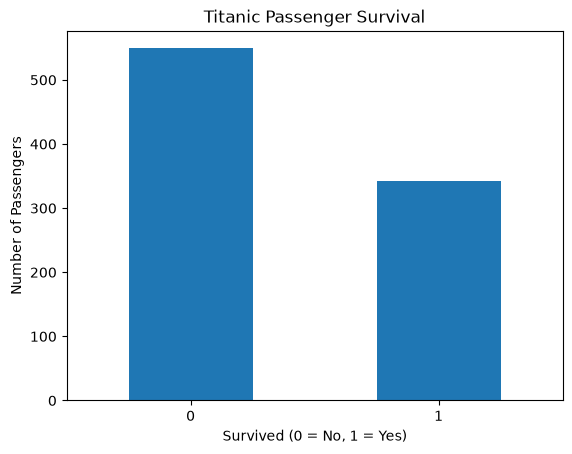

In [6]:
# We made a bar chart to compare survivors and the nonsurvivors.
titanic["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Titanic Passenger Survival")  # We added a title.
plt.xlabel("Survived (0 = No, 1 = Yes)")  # And a label for the outcomes.
plt.ylabel("Number of Passengers")  # We also labeled the count axis.
plt.xticks(rotation=0)  # We kept the labels horizontal.
plt.show()  #displays the chart.

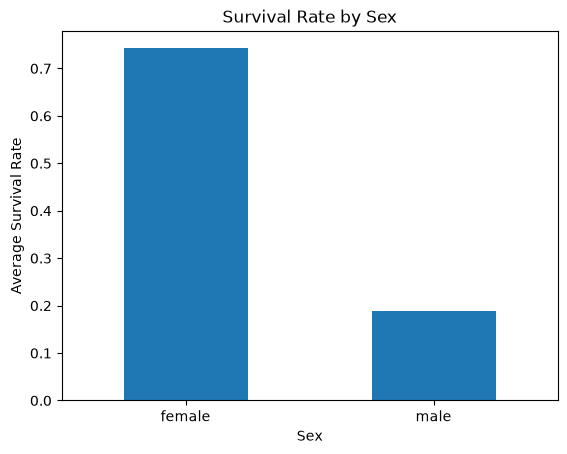

In [7]:
# This is just to compare survival rates for male and female passengers.
titanic.groupby("Sex")["Survived"].mean().plot(kind="bar")
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Average Survival Rate")
plt.xticks(rotation=0)
plt.show()

## 4. Prepare the data for machine learning
First we separate the input columns from the answer column. Then we split the passengers into training and testing sets before fitting the preprocessing steps so the test data doesnt influence how missing values are filled or how features are scaled.

In [8]:
# We used the train/test split that was shown in Chapter 3 calssification notebook.
from sklearn.model_selection import train_test_split

# We chose the same numeric and categorical attributes used in the provided Titanic example that we were given.
num_attribs = ["Age", "SibSp", "Parch", "Fare"]
cat_attribs = ["Pclass", "Sex", "Embarked"]

# X contains the inputs and y contains the known survival answers.
X = titanic[num_attribs + cat_attribs]
y = titanic["Survived"]

# We save 20% of the passengers for testing and train with the other 80% as done in class.
# random_state=42 makes the split the same each time we run it.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Used to check the size of each group.
print("Training passengers:", len(X_train))
print("Testing passengers:", len(X_test))

Training passengers: 712
Testing passengers: 179


The Titanic example notebook uses a numerical pipeline using median and standard scaling, plus a categorical pipeline with most-frequent imputation and one-hot encoding. We will use those same steps. The scaling makes numerical attributes more comparable, and one-hot encoding changes categories such as Sex and Embarked into numbers that the model can use.

In [9]:
from sklearn.pipeline import Pipeline  # used to group the preprocessing steps together.
from sklearn.impute import SimpleImputer  # used for filling the missing values.
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # used for scaling numbers and encoding the categories.
from sklearn.compose import ColumnTransformer  # used for applying different steps to different columns.

# We fill missing numerical values with the training median then scale them.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# We fill missing categories with the most common training value.
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("cat_encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# We combined the numeric and categorical preprocessing steps.
preprocess_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs)
])

In [10]:
# to learn missing value replacements, categories, and scaling values from the training data only.
X_train_prepared = preprocess_pipeline.fit_transform(X_train)

# to use those same learned steps on the test data without fitting again.
X_test_prepared = preprocess_pipeline.transform(X_test)

# to check how many rows and prepared features we now have.
print("Prepared training shape:", X_train_prepared.shape)
print("Prepared testing shape:", X_test_prepared.shape)

Prepared training shape: (712, 12)
Prepared testing shape: (179, 12)


## 5. Select a model and train it

In this section, we used a Random Forest Classifier to predict whether a passenger survived the Titanic. We trained our model using the prepared training data and then used the model to make predictions on the testing data.

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Creates and trains the Random Forest classification model
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42)
forest_clf.fit(X_train_prepared, y_train)

# Predicts the passenger survival using the testing data
y_pred = forest_clf.predict(X_test_prepared)

## 6. Fine-tune and evaluate the model

For this section, we evaluated how well our Random Forest Classification model performs. We use accuracy, precision, recall, and F1 scores to determine/measure its performance. We also use a confusion matrix to compare the predicted and actual survival outcomes, an ROC curve to evalue the model's ability to distinguish between the two classes, and cross-validation to check how constent the model performs. 

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculates the performance scores of the classification model we chose
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8156424581005587
Precision: 0.7887323943661971
Recall: 0.7567567567567568
F1 Score: 0.7724137931034483


[[90 15]
 [18 56]]


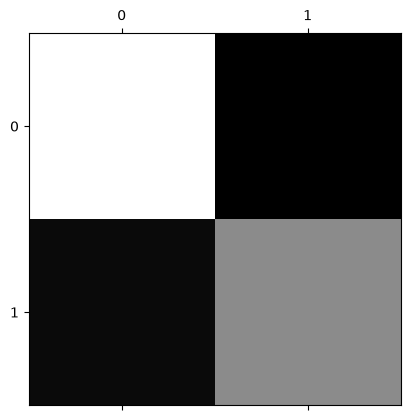

In [28]:
from sklearn.metrics import confusion_matrix

# This creates the confusion matrix 
conf_mx = confusion_matrix(y_test, y_pred)
print(conf_mx)

# Displays the confusion matrix 
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.show()

The confusion matrix compares the actual survival outcomes with the predicitons made by our model. In this graph, 0 represents passengers who did not survive, while 1 represents passengers who survived. The matrix shows how many passengers were correctly and incorrectly classified. 

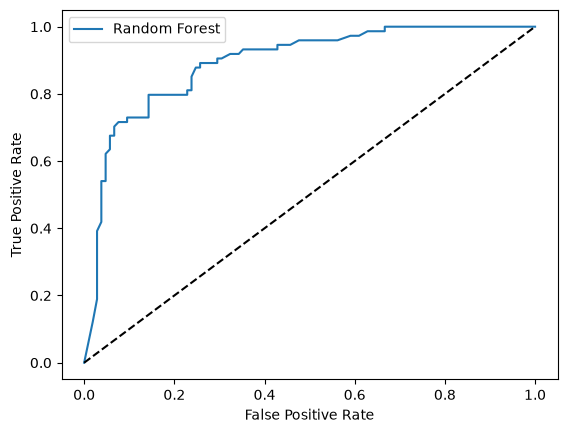

ROC AUC: 0.8923423423423423


In [26]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculates the predicted probability of survival
y_scores = forest_clf.predict_proba(X_test_prepared)[:, 1]

# Calculates the false positive and true positive rates
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Calculates the ROC AUC score
roc_auc = roc_auc_score(y_test, y_scores)

# Plots the ROC curve
plt.plot(fpr, tpr, label ="Random Forest")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

print("ROC AUC:", roc_auc)

In [23]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Combines the preprocessing steps with the Random Forest 
cv_model = Pipeline([("preprocessing", preprocess_pipeline), ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))])

# Uses 5-fold cross-validation to evaluate the model 
cv_scores = cross_val_score(cv_model, X_train, y_train, cv=5, scoring="accuracy")

# Displays the cross-validation and their average
print("Cross-validation score:", cv_scores)
print("Mean cross-validation accuracy:", cv_scores.mean())

Cross-validation score: [0.7972028  0.74825175 0.79577465 0.78169014 0.83802817]
Mean cross-validation accuracy: 0.7921895006402049


## 7. Present our solution

In [25]:
# Displaying the final evaluation scores of our Random Forest Classification model one more time
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(y_test, y_pred))
print("Test Recall:", recall_score(y_test, y_pred))
print("Test F1 Score:", f1_score(y_test, y_pred))
print("Test ROC AUC:", roc_auc)

Test Accuracy: 0.8156424581005587
Test Precision: 0.7887323943661971
Test Recall: 0.7567567567567568
Test F1 Score: 0.7724137931034483
Test ROC AUC: 0.8923423423423423


On our test set, our Random Forest Classifier model achieved an accuracy of approximately 81.6%, precision of 78.9%, recall of 75.7%, and an F1 score of 77.2%. Our ROC AUC score was approximately 89.2% as well. 